# Checkpoint — KMeans & DBSCAN

Dit notebook wordt automatisch gecheckt via pytest (GitHub Actions). De checks voeren je notebook uit en valideren of bepaalde variabelen bestaan en binnen de verwachte ranges vallen. **Je krijgt geen hints in de foutmeldingen: het is aan jou om correct werkende code te schrijven.**

## BELANGRIJK: gebruik exact de genoemde variabelennamen

De checks zoeken volgende variabelen in je notebook. Andere namen worden niet gezien:

- `best_k_wine` — de gekozen waarde van k voor de Wine-dataset (int)
- `silhouette_wine` — de silhouette score van die keuze (float)
- `image` — de ingeladen afbeelding (3D numpy-array)
- `n_colors` — het tuple van aantal kleuren `(10, 8, 6, 4, 2)`
- `segmented_imgs` — de lijst van gesegmenteerde afbeeldingen (5 elementen, zelfde vorm als `image`)
- `best_k_iris` — de gekozen waarde van k voor de Iris-dataset (int)
- `silhouette_iris` — de silhouette score van die keuze (float)
- `best_k_mall` — de gekozen waarde van k voor de Mall-dataset (int)
- `silhouette_mall` — de silhouette score van die keuze (float)
- `antwoord_iris` — meerkeuzevraag 1: `"A"`, `"B"`, `"C"` of `"D"`
- `antwoord_dbscan` — meerkeuzevraag 2: `"A"`, `"B"`, `"C"` of `"D"`

Gebruik overal `random_state=42` (en `n_init=10`) bij KMeans zodat je resultaten reproduceerbaar zijn en binnen de verwachte drempels vallen. Werk met de lokale afbeelding `images/butterfly.jpg` (er wordt niets gedownload).

## Oefening 1 — Wijn

Cluster de Wine-dataset zo optimaal mogelijk met KMeans. De dataset heeft 13 features op verschillende schalen, dus **schaal eerst met `StandardScaler`**.

Probeer verschillende waarden van `k`, bereken telkens de **silhouette score** en kies de `k` met de hoogste score.

Bewaar je keuze in `best_k_wine` en de bijhorende score in `silhouette_wine`.

In [68]:
import numpy as np
from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

wine = datasets.load_wine()
data = wine.data

# Schaal de data zodat alle features gelijk gewicht krijgen
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

K: 2, score: 0.5817500491982808
K: 3, score: 0.45994823920518635
K: 4, score: 0.38694104154427816
K: 5, score: 0.3459012795948778
K: 6, score: 0.31707940193569023
K: 7, score: 0.3201967939183684
 best K wine: 2 met score: 0.5817500491982808


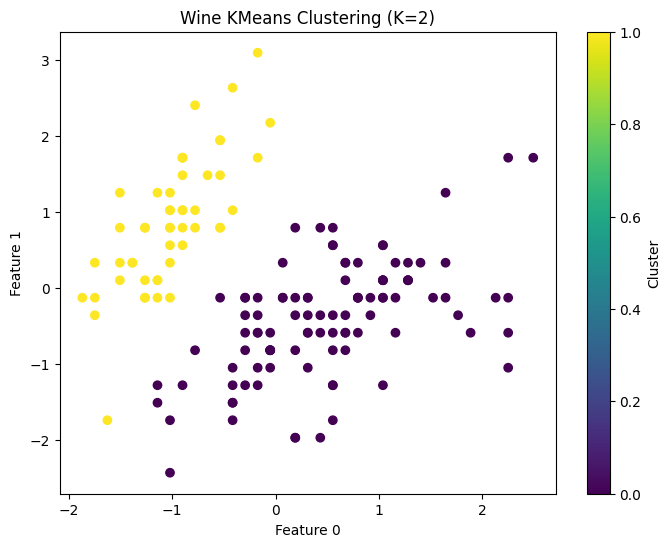

In [94]:
# TODO: bereken voor elke k in range(2, 8) de silhouette score (KMeans met
# random_state=42, n_init=10). Bewaar de k met de hoogste score in best_k_wine
# en die score in silhouette_wine.
best_k_wine = 2
silhouette_wine = 0.0

for k in range(2, 8):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(data_scaled)
    # labels = kmeans.fit_predict(data_scaled)
    score = silhouette_score(data_scaled, kmeans.labels_)
    print(f"K: {k}, score: {score}")
    if score > silhouette_wine:
        best_k_wine = k
        silhouette_wine = score

print(f" best K wine: {best_k_wine} met score: {silhouette_wine}")

import matplotlib.pyplot as plt

# Train KMeans with the best K
kmeans = KMeans(
    n_clusters=best_k_wine,
    n_init=10,
    random_state=42
)

labels = kmeans.fit_predict(data_scaled)

# Scatterplot using the first 2 features
plt.figure(figsize=(8, 6))

plt.scatter(
    data_scaled[:, 0],
    data_scaled[:, 1],
    c=labels,
    cmap="viridis"
)

plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
plt.title(f"Wine KMeans Clustering (K={best_k_wine})")

plt.colorbar(label="Cluster")
plt.show()
    

## Oefening 2 — Image Segmentation

We gebruiken clustering om een afbeelding in stukken met gelijkaardige kleuren te verdelen. Gebruik de lokale afbeelding `images/butterfly.jpg` (533×800 pixels, 3 kleurkanalen).

Hervorm de 3D-array tot een `(n_pixels, 3)` matrix met `reshape(-1, 3)`, train dan KMeans met `n_clusters` in `(10, 8, 6, 4, 2)` en vervang elke pixel door de centroidkleur van zijn cluster. Hervorm het resultaat terug naar de originele vorm.

Bewaar het tuple `n_colors = (10, 8, 6, 4, 2)` en de 5 gesegmenteerde afbeeldingen in `segmented_imgs`.

In [70]:
import numpy as np
from PIL import Image
from sklearn.cluster import KMeans

# Gebruik het lokale voorbeeldbeeld (geen download nodig)
image = np.asarray(Image.open('images/butterfly.jpg'))
print('image shape:', image.shape)

# Hervorm de 3D-array (pixels, breedte, kanalen) naar een (n_pixels, 3) matrix
X = image.reshape(-1, 3)

vectorized = np.float32(X)


image shape: (533, 800, 3)


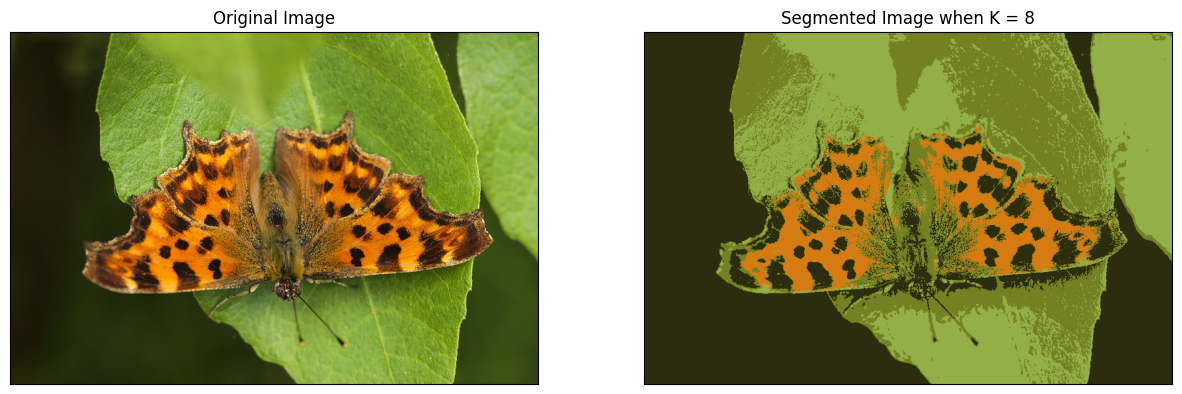

In [71]:
import matplotlib.pyplot as plt

# TODO: train voor elk aantal kleuren een KMeans (random_state=42, n_init=10)
# op X, vervang elke pixel door de centroidkleur van zijn cluster en hervorm
# terug naar image.shape. Bewaar alles in segmented_imgs (volgorde van n_colors).
n_colors = (10, 8, 6, 4, 2)
segmented_imgs = []
for n_clusters in n_colors:
    kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X)
    segmented_img = kmeans.cluster_centers_[labels]  # aan te passen
    segmented_imgs.append(segmented_img.reshape(image.shape).astype(np.uint8))

figure_size = 15
plt.figure(figsize=(figure_size,figure_size))
plt.subplot(1,2,1),plt.imshow(image)
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(1,2,2),plt.imshow(segmented_imgs[3])
plt.title('Segmented Image when K = 8'), plt.xticks([]), plt.yticks([])
plt.show()

## Oefening 3 — KMeans vs DBSCAN op Iris

De Iris-dataset bevat 3 soorten die in de feature-ruimte goed gescheiden, **bolvormige** clusters van **gelijkaardige dichtheid** vormen.

Pas zowel KMeans (verschillende `k`) als DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_iris` en de hoogste silhouette in `silhouette_iris`. Beantwoord daarna vraag 1 in `antwoord_iris`.

In [95]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

iris = load_iris()
data_scaled = StandardScaler().fit_transform(iris.data)

best_k_iris = 2
silhouette_iris_km = 0.0

silhouette_iris_db = 0.0
best_eps_iris = 0
best_minsamples_iris = 0

# KMeans
for k in range(2, 6):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(data_scaled)
    # labels = kmeans.fit_predict(data_scaled)
    score = silhouette_score(data_scaled, kmeans.labels_)
    print(f"K: {k} score: {score}")
    if silhouette_iris_km < score:
        silhouette_iris_km = score
        best_k_iris = k

print(f"best K : {best_k_iris} with score: {silhouette_iris_km}")

# DBSCAN
for eps in np.arange(0.1, 1.1, 0.1):
    for min_sample in range(1, 6):

        db = DBSCAN(eps=eps, min_samples=min_sample)
        labels = db.fit_predict(data_scaled)
        # Don't count noise (-1) as a cluster
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        if n_clusters >= 2:
            score = silhouette_score(data_scaled, labels)
            print(
                f"eps: {eps}, "
                f"min_samples: {min_sample}, "
                f"score: {score}"
            )
            if silhouette_iris_db < score:
                silhouette_iris_db = score
                best_eps_iris = eps
                best_minsamples_iris = min_sample
# print(
#     f"best eps: {best_eps_iris}, "
#     f"best min_samples: {best_minsamples_iris}, "
#     f"with score: {silhouette_iris_db}"
# )


print()

print()

K: 2 score: 0.5817500491982808
K: 3 score: 0.45994823920518635
K: 4 score: 0.38694104154427816
K: 5 score: 0.3459012795948778
best K : 2 with score: 0.5817500491982808
eps: 0.1, min_samples: 1, score: 0.013333333333333334
eps: 0.2, min_samples: 1, score: 0.11434853799544459
eps: 0.2, min_samples: 2, score: -0.37112581511214593
eps: 0.2, min_samples: 3, score: 0.08705841329683042
eps: 0.2, min_samples: 4, score: 0.02514589229455723
eps: 0.30000000000000004, min_samples: 1, score: 0.12841291799173957
eps: 0.30000000000000004, min_samples: 2, score: -0.06194379641303411
eps: 0.30000000000000004, min_samples: 3, score: -0.14729986910161358
eps: 0.30000000000000004, min_samples: 4, score: -0.20734607362884194
eps: 0.30000000000000004, min_samples: 5, score: -0.1941947686285083
eps: 0.4, min_samples: 1, score: 0.05467025016818084
eps: 0.4, min_samples: 2, score: 0.0858214387089518
eps: 0.4, min_samples: 3, score: 0.15125088552326663
eps: 0.4, min_samples: 4, score: 0.08194615025833869
eps: 0

In [99]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

iris = load_iris()
data_scaled = StandardScaler().fit_transform(iris.data)

best_k_iris = 2
silhouette_iris_km = 0.0

silhouette_iris_db = 0.0
best_eps_iris = 0
best_minsamples_iris = 0

# KMeans
for k in range(2, 6):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(data_scaled)
    score = silhouette_score(data_scaled, kmeans.labels_)
    print(f"K: {k} score: {score}")
    if silhouette_iris_km < score:
        silhouette_iris_km = score
        best_k_iris = k

print(f"best K : {best_k_iris} with score: {silhouette_iris_km}")

# DBSCAN
for eps in np.arange(0.1, 1.1, 0.1):
    for min_sample in range(1, 6):

        db = DBSCAN(eps=eps, min_samples=min_sample).fit(data_scaled)
        # Don't count noise (-1) as a cluster
        n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
        if n_clusters >= 2:
            score = silhouette_score(data_scaled, db.labels_)
            if silhouette_iris_db < score:
                silhouette_iris_db = score
                best_eps_iris = eps
                best_minsamples_iris = min_sample
                print(f"eps: {eps}, min_samples: {min_sample}, score: {score}")
# print(
#     f"best eps: {best_eps_iris}, "
#     f"best min_samples: {best_minsamples_iris}, "
#     f"with score: {silhouette_iris_db}"
# )


print()
print()
print()

print(f"K: {best_k_iris}, score: {silhouette_iris_km}")
print(f"eps: {best_eps_iris}, score: {silhouette_iris_db}")


K: 2 score: 0.5817500491982808
K: 3 score: 0.45994823920518635
K: 4 score: 0.38694104154427816
K: 5 score: 0.3459012795948778
best K : 2 with score: 0.5817500491982808
eps: 0.1, min_samples: 1, score: 0.013333333333333334
eps: 0.2, min_samples: 1, score: 0.11434853799544459
eps: 0.30000000000000004, min_samples: 1, score: 0.12841291799173957
eps: 0.4, min_samples: 3, score: 0.15125088552326663
eps: 0.5, min_samples: 3, score: 0.15971036873870176
eps: 0.5, min_samples: 4, score: 0.36457435678297523
eps: 0.6, min_samples: 5, score: 0.4027617471797909
eps: 0.7000000000000001, min_samples: 2, score: 0.4515664736593728
eps: 0.7000000000000001, min_samples: 3, score: 0.5080668523761808
eps: 0.7000000000000001, min_samples: 5, score: 0.523400848673573
eps: 1.0, min_samples: 4, score: 0.5382884306788227



K: 2, score: 0.5817500491982808
eps: 1.0, score: 0.5382884306788227


## Oefening 4 — KMeans vs DBSCAN op Mall

De Mall-dataset (`data/Mall_Customers.csv`) bevat klanten met `Age`, `Annual Income (k$)` en `Spending Score (1-100)`. De clusters hebben **sterk verschillende dichtheden**, waardoor DBSCAN het vaak moeilijk heeft.

Pas KMeans (verschillende `k`) en DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_mall` en de hoogste silhouette in `silhouette_mall`. Beantwoord daarna vraag 2 in `antwoord_dbscan`.

best K : 6 with score: 0.4284167762892593
eps: 0.1, min_samples: 1, score: 0.022028669320724323
eps: 0.2, min_samples: 1, score: 0.12991759263057104
eps: 0.4, min_samples: 2, score: 0.1604429394842519
eps: 0.5, min_samples: 5, score: 0.18451372756506046
eps: 0.5, min_samples: 6, score: 0.2073279591655691
eps: 0.5, min_samples: 7, score: 0.2236154132178232
eps: 0.6, min_samples: 7, score: 0.25683324151472064
eps: 0.6, min_samples: 9, score: 0.28578386633235126
eps: 0.6, min_samples: 10, score: 0.2904356073760902
best eps : 0.6, best sampels: 10 with score: 0.2904356073760902


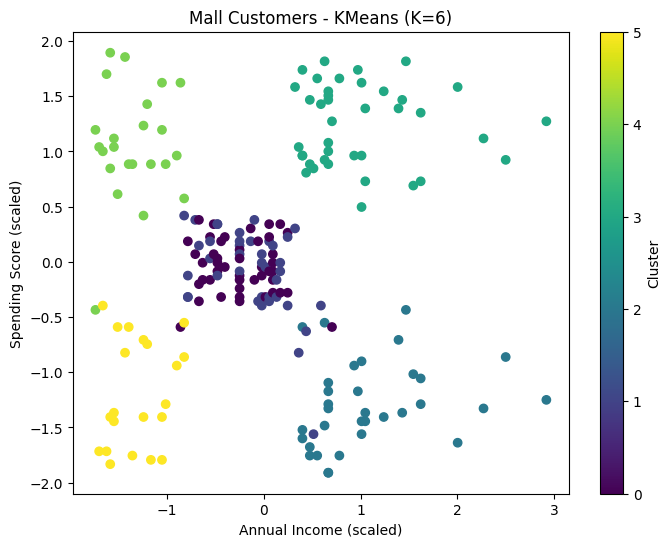

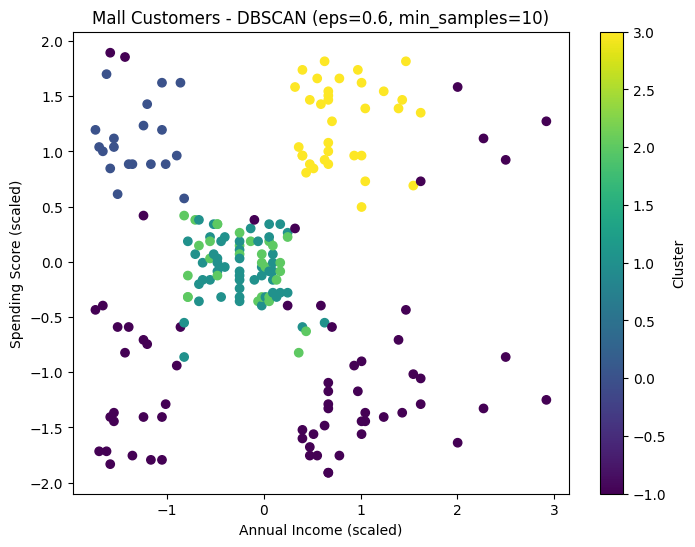

In [103]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

mall = pd.read_csv('data/Mall_Customers.csv')
features = mall[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]
data_scaled = StandardScaler().fit_transform(features)

# TODO: vergelijk KMeans (verschillende k's) met DBSCAN (verschillende
# eps/min_samples) via de silhouette score. Bewaar de gekozen k in best_k_mall
# en de hoogste silhouette in silhouette_mall.
best_k_mall = 5
silhouette_mall = 0.0

for k in range(2, 8):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(data_scaled)
    # labels = kmeans.fit_predict(data_scaled)
    score = silhouette_score(data_scaled, kmeans.labels_)
    # print(f"K: {k} score: {score}")
    if silhouette_mall < score:
        silhouette_mall = score
        best_k_mall = k

print(f"best K : {best_k_mall} with score: {silhouette_mall}")


silhouette_mall = 0.0
best_eps_mall = 0.0
best_minsamples_mall = 0.0

# DBSCAN
for eps in np.arange(0.1, 1.1, 0.1):
    for min_sample in range(1, 20):

        db = DBSCAN(eps=eps, min_samples=min_sample).fit(data_scaled)
        # Don't count noise (-1) as a cluster
        n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
        if n_clusters >= 2:
            score = silhouette_score(data_scaled, db.labels_)
            if silhouette_mall < score:
                silhouette_mall = score
                best_eps_mall = eps
                best_minsamples_mall = min_sample
                print(f"eps: {eps}, min_samples: {min_sample}, score: {score}")
print(f"best eps : {best_eps_mall}, best sampels: {best_minsamples_mall} with score: {silhouette_mall}")

import matplotlib.pyplot as plt

# -------------------------
# KMeans with best K
# -------------------------
kmeans = KMeans(
    n_clusters=best_k_mall,
    n_init=10,
    random_state=42
)

kmeans_labels = kmeans.fit_predict(data_scaled)


# -------------------------
# DBSCAN with best parameters
# -------------------------
db = DBSCAN(
    eps=best_eps_mall,
    min_samples=int(best_minsamples_mall)
)

dbscan_labels = db.fit_predict(data_scaled)


# -------------------------
# Plot KMeans
# -------------------------
plt.figure(figsize=(8, 6))

plt.scatter(
    data_scaled[:, 1],  # Annual Income
    data_scaled[:, 2],  # Spending Score
    c=kmeans_labels,
    cmap="viridis"
)

plt.xlabel("Annual Income (scaled)")
plt.ylabel("Spending Score (scaled)")
plt.title(f"Mall Customers - KMeans (K={best_k_mall})")
plt.colorbar(label="Cluster")

plt.show()


# -------------------------
# Plot DBSCAN
# -------------------------
plt.figure(figsize=(8, 6))

plt.scatter(
    data_scaled[:, 1],  # Annual Income
    data_scaled[:, 2],  # Spending Score
    c=dbscan_labels,
    cmap="viridis"
)

plt.xlabel("Annual Income (scaled)")
plt.ylabel("Spending Score (scaled)")
plt.title(
    f"Mall Customers - DBSCAN "
    f"(eps={best_eps_mall:.1f}, min_samples={int(best_minsamples_mall)})"
)
plt.colorbar(label="Cluster")

plt.show()

## Meerkeuzevragen

### Vraag 1 — Iris
Op de Iris-dataset haalt KMeans een veel hogere silhouette score dan DBSCAN. Wat is de belangrijkste reden?

- **A)** De clusters zijn bolvormig en hebben een gelijkaardige dichtheid, waarvoor KMeans goed geschikt is; DBSCAN kampt met de dichtheidsverschillen.
- **B)** KMeans werkt zonder features te standaardiseren.
- **C)** DBSCAN kan nooit meer dan 2 clusters vinden.
- **D)** KMeans kent het aantal clusters op voorhand, en dat is altijd beter.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_iris`.

### Vraag 2 — DBSCAN
Wanneer is DBSCAN een betere keuze dan KMeans?

- **A)** Wanneer de clusters een onregelmatige, niet-bolvormige vorm hebben of er outliers/ruis zijn.
- **B)** Wanneer alle clusters bolvormig en even groot zijn.
- **C)** Wanneer je altijd precies `k` clusters nodig hebt.
- **D)** Wanneer de dataset klein is en je snel wilt clusteren.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_dbscan`.

In [75]:
# Vraag 1: antwoord_iris = "A", "B", "C" of "D"
antwoord_iris = "A"

# Vraag 2: antwoord_dbscan = "A", "B", "C" of "D"
antwoord_dbscan = "A"
